In [2]:
import json, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from optbinning import BinningProcess, Scorecard
from optbinning.scorecard import plot_auc_roc, plot_ks
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

In [3]:
df = pd.read_csv('data/dataset_msp_credit.csv', encoding='utf-8-sig')
df = df[df.in_model_sample == 1]
train, test = df[df.split == 'train'], df[df.split == 'test']
sel = json.load(open('model/selected_features.json', encoding='utf-8'))
F = sel['features']

def bfp(features, cat):
    """Настройки биннинга: монотонность и ручные границы для просрочек."""
    p = {f: {'monotonic_trend': 'auto_asc_desc'} for f in features if f not in cat}
    if 'current_overdue_days' in p:
        p['current_overdue_days'] = {'user_splits': [0.5, 29.5], 'min_bin_size': 0.005}
    if 'overdue_30plus_flag_24m' in p:
        p['overdue_30plus_flag_24m'] = {'user_splits': [0.5], 'min_bin_size': 0.005}
    return p

In [4]:
# подбор C и штрафа: кросс-валидация по времени, биннинг внутри Pipeline 
tr_sorted = train.sort_values('application_date')
cat = [f for f in F if f in sel['categorical']]

pipe = Pipeline([
    ('bin', BinningProcess(F, categorical_variables=cat, max_n_bins=6, 
                           min_bin_size=0.025,
                           binning_fit_params=bfp(F, cat))),
    ('lr', LogisticRegression(max_iter=1000, solver='liblinear')),
])
grid = {'lr__C': [0.001, 0.01, 0.1, 1, 10], 'lr__penalty': ['l1', 'l2']}

gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=TimeSeriesSplit(n_splits=5), 
                  n_jobs=-1, verbose=1)
gs.fit(tr_sorted[F], tr_sorted.default_12m)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


c:\Users\user\Downloads\msp-ml1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lr__C': [0.001, 0.01, ...], 'lr__penalty': ['l1', 'l2']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_se

In [5]:
# лучшие параметры
print('лучшие параметры:', gs.best_params_)
print('Gini на кросс-валидации:', round(2 * gs.best_score_ - 1, 4))

лучшие параметры: {'lr__C': 0.1, 'lr__penalty': 'l2'}
Gini на кросс-валидации: 0.5778


In [6]:
def make_lr():
    """Логрегрессия с лучшими параметрами из GridSearch."""
    return LogisticRegression(max_iter=1000, solver='liblinear',
                              C=gs.best_params_['lr__C'], 
                              penalty=gs.best_params_['lr__penalty'])

def fit_scorecard(features):
    """Биннинг + логрегрессия + баллы (PDO 20, 600 при 50:1)."""
    cat = [f for f in features if f in sel['categorical']]
    bp = BinningProcess(features, categorical_variables=cat, max_n_bins=6, 
                        min_bin_size=0.025,
                        binning_fit_params=bfp(features, cat))
    sc = Scorecard(binning_process=bp, estimator=make_lr(),
                   scaling_method='pdo_odds', 
                   scaling_method_params={'pdo': 20, 'odds': 50, 
                                          'scorecard_points': 600},
                   reverse_scorecard=False)
    return sc.fit(train[features], train.default_12m)

sc = fit_scorecard(F)
table = sc.table(style='detailed')
table[['Variable', 'Bin', 'Count (%)', 'Event rate', 'WoE', 'Coefficient', 
       'Points']].head(25)

c:\Users\user\Downloads\msp-ml1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Variable,Bin,Count (%),Event rate,WoE,Coefficient,Points
0,zero_balance_days_90d,"(-inf, 0.50)",0.116982,0.025400,1.333401,-0.163761,22.601084
1,zero_balance_days_90d,"[0.50, 1.50)",0.165752,0.040140,0.860543,-0.163761,20.366763
2,zero_balance_days_90d,"[1.50, 3.50)",0.301983,0.063743,0.373162,-0.163761,18.063819
3,zero_balance_days_90d,"[3.50, 6.50)",0.225761,0.110730,-0.230554,-0.163761,15.211180
4,zero_balance_days_90d,"[6.50, 8.50)",0.069634,0.159555,-0.652319,-0.163761,13.218280
5,zero_balance_days_90d,"[8.50, inf)",0.087850,0.249265,-1.211326,-0.163761,10.576894
6,zero_balance_days_90d,Special,0.000000,0.000000,0.000000,-0.163761,16.300578
7,zero_balance_days_90d,Missing,0.032039,0.096774,-0.080271,-0.163761,16.300578
0,dscr_new,"(-inf, 0.07)",0.071119,0.237965,-1.149997,-0.368498,4.073100
1,dscr_new,"[0.07, 0.46)",0.117111,0.163817,-0.683765,-0.368498,9.030367


In [7]:
# правильный знак — отрицательный; >0 и =0 (обнулён l1) удаляем и переобучаем
removed = []
while True:
    coef = sc.table(style='detailed').groupby('Variable').Coefficient.first()
    wrong = coef[coef >= 0]                    
    if wrong.empty: break
    worst = wrong.idxmax() 
    removed.append((worst, round(float(wrong.max()), 4)))
    F.remove(worst)
    sc = fit_scorecard(F)
table = sc.table(style='detailed')

c:\Users\user\Downloads\msp-ml1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [8]:
# что удалили
print('удалены:', removed)
print('итого признаков в скоркарте:', len(F))

удалены: [(np.str_('loan_product'), 0.4421)]
итого признаков в скоркарте: 33


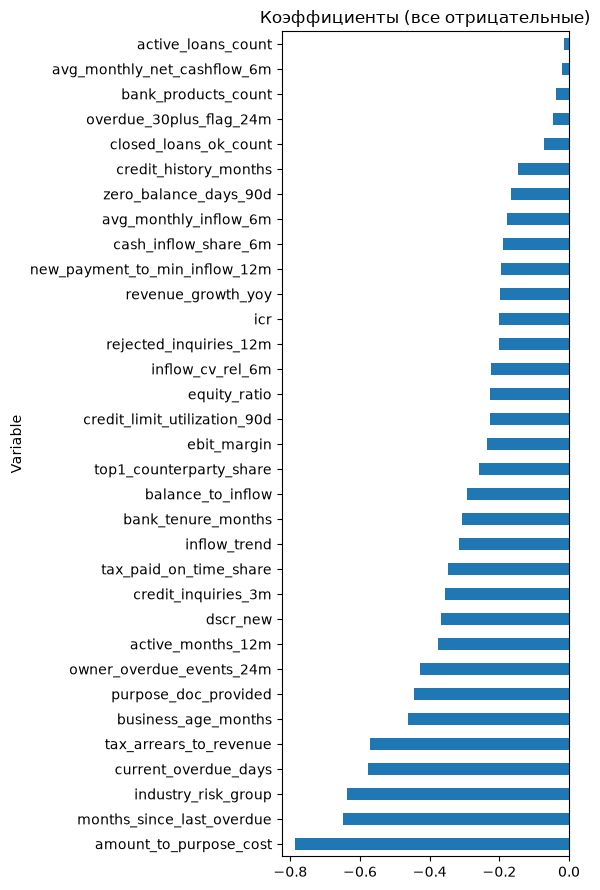

In [9]:
# коэффициенты итоговой модели
coef = table.groupby('Variable').Coefficient.first().sort_values()
coef.plot.barh(figsize=(6, 9), title='Коэффициенты (все отрицательные)')
plt.tight_layout()

In [10]:
def ks(y, s):
    """KS: макс. разрыв накопленных долей плохих и хороших."""
    o = np.argsort(s) 
    y = np.asarray(y)[o]
    return np.max(np.abs(np.cumsum(y) / y.sum() - np.cumsum(1 - y) 
                         / (1 - y).sum()))

def hosmer_lemeshow(y, p, g=10):
    """Хосмер–Лемешоу: совпадает ли PD с фактом по 10 группам."""
    d = pd.DataFrame({'y': y, 'p': p}) 
    d['g'] = pd.qcut(d.p.rank(method='first'), 
                             g, labels=False)
    a = d.groupby('g').agg(o=('y', 'sum'), e=('p', 'sum'), n=('y', 'size'))
    return (((a.o - a.e) ** 2) / (a.e * (1 - a.e / a.n))).sum()

def psi(a, b, n=10):
    """PSI: сдвиг распределения баллов между выборками."""
    e = np.unique(np.quantile(a, np.linspace(0, 1, n + 1)))
    e[0], e[-1] = -np.inf, np.inf
    pa, pb = np.histogram(a, e)[0] / len(a) + 1e-6, np.histogram(b, e)[0] / len(b) + 1e-6
    return np.sum((pa - pb) * np.log(pa / pb))


In [11]:
# факт, PD и баллы для обеих выборок
y_tr, y_te = train.default_12m.values, test.default_12m.values
p_tr, p_te = sc.predict_proba(train[F])[:, 1], sc.predict_proba(test[F])[:, 1]
s_tr, s_te = sc.score(train[F]), sc.score(test[F])
n1, n0 = y_te.sum(), (1 - y_te).sum()

In [12]:
# метрики на проверке (последние 6 месяцев)
metrics = pd.Series({
    'Gini обучение': 2 * roc_auc_score(y_tr, p_tr) - 1,
    'Gini проверка': 2 * roc_auc_score(y_te, p_te) - 1,
    'KS проверка': ks(y_te, p_te), 'KS критическое (α=0,05)': 1.36 * math.sqrt((n1 + n0) / (n1 * n0)),
    'Хосмер–Лемешоу': hosmer_lemeshow(y_te, p_te), 'HL критическое (df=8)': 15.51,
    'PSI обучение→проверка': psi(s_tr, s_te),
}).round(4)
metrics

Gini обучение               0.6190
Gini проверка               0.6116
KS проверка                 0.4823
KS критическое (α=0,05)     0.0637
Хосмер–Лемешоу              9.9544
HL критическое (df=8)      15.5100
PSI обучение→проверка       0.0034
dtype: float64

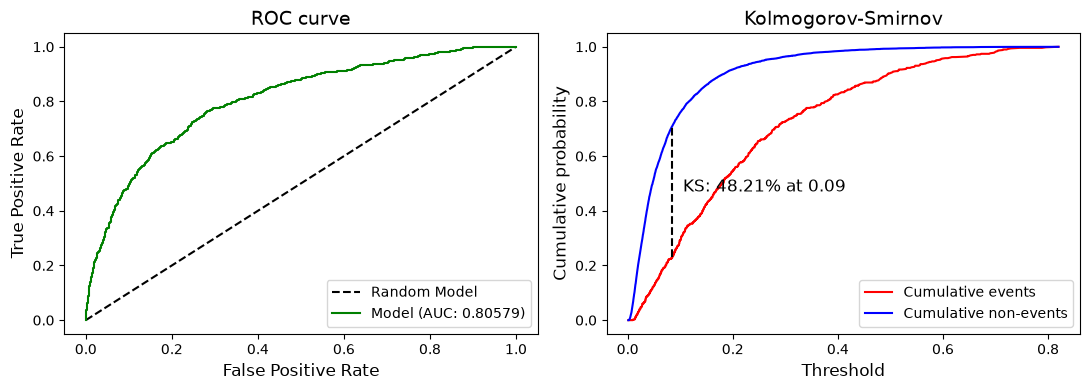

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
plt.sca(ax[0]); plot_auc_roc(y_te, p_te)
plt.sca(ax[1]); plot_ks(y_te, p_te); plt.tight_layout()

In [14]:
# качество отдельно по продуктам
pd.DataFrame([{'продукт': p, 'заявок': int(m.sum()), 'дефолтов': 
               int(y_te[m].sum()),
               'Gini': 2 * roc_auc_score(y_te[m], p_te[m]) - 1, 
               'средняя PD': p_te[m].mean(), 'факт': y_te[m].mean()}
              for p in test.loan_product.unique() for m in [(test.loan_product == p).values]]).round(3)

,продукт,заявок,дефолтов,Gini,средняя PD,факт
0,loan,3151,352,0.605,0.108,0.112
1,overdraft,945,79,0.610,0.065,0.084
2,line,1079,74,0.619,0.074,0.069


дециль,1,2,3,4,5,6,7,8,9,10
PD,0.009,0.017,0.026,0.035,0.046,0.061,0.082,0.115,0.175,0.365
факт,0.004,0.027,0.029,0.031,0.042,0.056,0.075,0.116,0.201,0.394


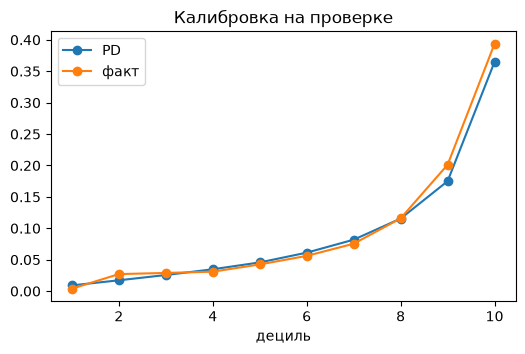

In [15]:
# калибровка: средняя PD против факта по децилям
cal = pd.DataFrame({'p': p_te, 'y': y_te})
cal['дециль'] = pd.qcut(cal.p.rank(method='first'), 10, labels=False) + 1
c = cal.groupby('дециль').agg(PD=('p', 'mean'), факт=('y', 'mean'))
c.plot(marker='o', figsize=(6, 3.5), title='Калибровка на проверке')
c.round(3).T

In [16]:
# сдвиг константы под новую долю дефолтов: ранжирование не меняется
logit = lambda p: np.log(p / (1 - p))
delta = logit(y_te.mean()) - logit(p_te.mean())
p_te_adj = 1 / (1 + np.exp(-(logit(p_te) + delta)))
pd.Series({'HL до сдвига': hosmer_lemeshow(y_te, p_te), 
           'HL после сдвига константы': hosmer_lemeshow(y_te, p_te_adj),
           'сдвиг константы': delta, 'HL на обучении': 
           hosmer_lemeshow(y_tr, p_tr)}).round(3)

HL до сдвига                 9.954
HL после сдвига константы    8.299
сдвиг константы              0.052
HL на обучении               7.775
dtype: float64

In [17]:
# зоны: зелёная ≤ 0,5× базовой доли, красная ≥ 1,5×, жёлтая ≥ 10% заявок
base = y_tr.mean()
grid_s = np.quantile(s_tr, np.linspace(0.05, 0.95, 91))
green = min(g for g in grid_s if y_tr[s_tr >= g].mean() <= 0.5 * base)
red = max(g for g in grid_s if g < green and ((s_tr >= g) & (s_tr < green)).mean() >= 0.10
          and y_tr[s_tr < g].mean() >= 1.5 * base)
zone = lambda s: np.where(s >= green, 'green', np.where(s < red, 
                                                        'red', 'yellow'))
print(f'красная: балл < {red:.1f};  зелёная: балл ≥ {green:.1f}')
z = pd.DataFrame({'зона': zone(s_te), 'y': y_te}).groupby('зона').y.agg(заявок='size', доля_дефолтов='mean')
z['доля_заявок'] = z.заявок / z.заявок.sum()
z.loc[['green', 'yellow', 'red']].round(3)

красная: балл < 518.2;  зелёная: балл ≥ 540.0


,заявок,доля_дефолтов,доля_заявок
зона,,,
green,4115,0.047,0.795
yellow,646,0.218,0.125
red,414,0.413,0.080


Text(0.5, 0, 'балл')

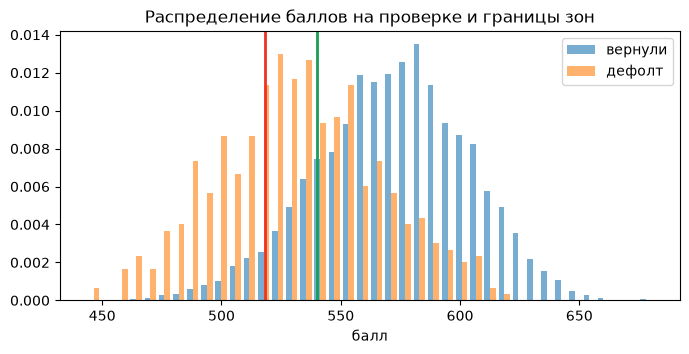

In [18]:
plt.figure(figsize=(8, 3.5))
plt.hist([s_te[y_te == 0], s_te[y_te == 1]], bins=40, density=True, alpha=.6, label=['вернули', 'дефолт'])
for v, c in ((red, '#ef3124'), (green, '#1a9e55')): plt.axvline(v, c=c, lw=2)
plt.legend() 
plt.title('Распределение баллов на проверке и границы зон') 
plt.xlabel('балл')

In [19]:
# изменяемые признаки и тексты советов; таблица баллов по признакам
ACTIONABLE = {
    'dscr_new': 'Уменьшите сумму или увеличьте срок: платёж должен быть посильным для ваших оборотов',
    'new_payment_to_min_inflow_12m': 'Уменьшите платёж: его должно хватать даже в самый слабый месяц',
    'amount_to_purpose_cost': 'Приведите сумму кредита в соответствие со стоимостью цели',
    'purpose_doc_provided': 'Приложите документ по цели: договор, счёт или смету',
    'tax_paid_on_time_share': 'Платите налоги в срок',
    'current_overdue_days': 'Погасите текущую просрочку по кредитам',
    'tax_arrears_to_revenue': 'Погасите задолженность по налогам',
}
pts = {v: g.reset_index(drop=True) for v, g in table.groupby('Variable')}

In [20]:
def points_of(row):
    """Баллы клиента по каждому признаку."""
    out = {}
    for f in F:
        ob = sc.binning_process_.get_binned_variable(f)
        idx = int(ob.transform(pd.Series([row[f]]), metric='indices')[0])
        out[f] = pts[f].Points.iloc[idx]
    return out

def relevant(f, v):
    """Есть ли у клиента что исправить по признаку."""
    if v is None or pd.isna(v): return False
    return {'purpose_doc_provided': v == 0, 'amount_to_purpose_cost': v > 1.05,
            'current_overdue_days': v > 0, 'tax_arrears_to_revenue': v > 0,
            'tax_paid_on_time_share': v < 0.98}.get(f, True)

def advice(row, top=3):
    """Топ-3 простых совета по приросту баллов."""
    p, recs = points_of(row), []
    for f, text in ACTIONABLE.items():
        if f not in pts or not relevant(f, row[f]): continue
        t = pts[f][~pts[f].Bin.astype(str).isin(['Special', 'Missing'])]
        better = t.Points[t.Points > p[f]]
        if len(better): recs.append((better.min() - p[f], text))
    return [t for _, t in sorted(recs, reverse=True)[:top]]

mean_pts = {f: pts[f].Points.values @ pts[f]['Count (%)'].values for f in F}
def helps_hurts(row, n=3):
    """Что выше среднего (помогает) и ниже (мешает)."""
    d = sorted(((f, v - mean_pts[f]) for f, v in points_of(row).items()), 
               key=lambda x: x[1])
    return [(f, round(v, 1)) for f, v in d[::-1][:n] if v > 0], [(f, round(v, 1)) for f, v in d[:n] if v < 0]

In [21]:
# политика и продукты 
POLICY = {'key_rate': 14.0, 'opex_margin_pp': 3.5, 'scoring_rate': 0.20, 
          'min_dscr': 1.2, 'lgd': 0.45}
PRODUCTS = {
    'loan': {'u': 1.0, 'n': None, 'terms': [6, 12, 18, 24, 36, 48, 60], 
             'margin_add': 0.0},
    'overdraft': {'u': 0.5, 'n': 12,   'terms': [12], 'margin_add': 1.5},
    'line': {'u': 0.5, 'n': 12,   'terms': [12, 24, 36], 'margin_add': 0.75},
}
ZONE_RU = {'green': 'зелёная', 'yellow': 'жёлтая', 'red': 'красная'}

def ka(rate, n):
    """Коэффициент аннуитета."""
    r = rate / 12
    return r / (1 - (1 + r) ** -n)

def payment(product, amount, term, rate):
    """Месячный платёж: u · сумма · Ka."""
    p = PRODUCTS[product]
    return p['u'] * amount * ka(rate, p['n'] or term)

def min_inflow_of(row):
    """Минимальные месячные поступления за год (из исходной заявки)."""
    p0 = payment(row.loan_product, row.loan_amount, row.term_months, 
                 POLICY['scoring_rate'])
    r = row.new_payment_to_min_inflow_12m
    return np.nan if pd.isna(r) or r == 0 else p0 / r

def with_request(row, amount, term):
    """Клиент с новой суммой и сроком: пересчёт признаков заявки."""
    r = row.copy()
    p = payment(r.loan_product, amount, term, POLICY['scoring_rate'])
    cf, d, g = (r.avg_monthly_net_cashflow_6m,
                r.existing_debt_payment_m,
                r.guarantees_given_payment_m)
    r['dscr_new'] = np.nan if pd.isna(cf) else min(cf / (p + d + 0.5 * g), 5.0)
    mi = min_inflow_of(row)
    r['new_payment_to_min_inflow_12m'] = np.nan if pd.isna(mi) else p / mi
    if not pd.isna(r.purpose_cost) and r.purpose_cost > 0:
        r['amount_to_purpose_cost'] = amount / r.purpose_cost
    r['loan_amount'], r['term_months'] = amount, term
    return r

BORDER = 5

def normalize(row):
    """Согласует историю просрочек с текущей просрочкой."""
    r = row.copy()
    if r.current_overdue_days > 0:
        r['months_since_last_overdue'] = 0
        r['overdue_events_24m'] = max(1, r.overdue_events_24m)
        if r.current_overdue_days >= 30:
            r['overdue_30plus_flag_24m'] = 1
    return r

def apply_rules(row, s, z):
    """Правила политики поверх модели: (зона, причина)."""
    if row.current_overdue_days >= 30:
        return 'red', 'текущая просрочка 30+ дней'
    if row.current_overdue_days > 0 and z == 'green':
        return 'yellow', 'есть текущая просрочка'
    if z == 'green' and s - green <= BORDER:
        return 'yellow', 'балл у границы зелёной зоны'
    if z == 'red' and red - s <= BORDER:
        return 'yellow', 'балл у границы красной зоны'
    return z, None

def evaluate(row):
    """Балл, PD, зона с правилами, ставка, платёж, DSCR по реальной ставке."""
    row = normalize(row)
    X = row[F].to_frame().T.infer_objects()
    s = float(sc.score(X)[0])
    p = float(sc.predict_proba(X)[0, 1])
    rate = POLICY['key_rate'] + p * POLICY['lgd'] * 100 + POLICY['opex_margin_pp'] + PRODUCTS[row.loan_product]['margin_add']
    pay = payment(row.loan_product, row.loan_amount, row.term_months, rate / 100)
    cf = row.avg_monthly_net_cashflow_6m
    dscr = np.nan if pd.isna(cf) else cf / (pay + row.existing_debt_payment_m + 0.5 * row.guarantees_given_payment_m)
    z, reason = apply_rules(row, s, str(zone(np.array([s]))[0]))
    return {'score': round(s, 1), 'pd': round(p, 4), 'zone': z, 'reason': reason,
            'rate': round(rate, 2), 'payment': round(pay), 'dscr_final': None if pd.isna(dscr) else round(dscr, 2)}

def ok(e, need_zone='green'):
    """Проходит ли вариант: зона не хуже нужной и DSCR ≥ 1,2."""
    order = {'green': 2, 'yellow': 1, 'red': 0}
    return order[e['zone']] >= order[need_zone] and e['dscr_final'] is not None and e['dscr_final'] >= POLICY['min_dscr']

def find_amount(row):
    """Сумма как просил, иначе наибольшая проходящая (сначала зелёная, потом жёлтая)."""
    asked, term0 = float(row.loan_amount), int(row.term_months)
    e0 = evaluate(row)
    if ok(e0):
        return {'decision': 'одобрить как просил', 'amount': asked, 'term': term0, **e0}
    terms = sorted(set(PRODUCTS[row.loan_product]['terms']) | {term0}, key=lambda t: (t != term0, t))
    for need, label in (('green', 'одобрить меньшую сумму'), ('yellow', 'к оператору с меньшей суммой')):
        best = None
        for t in terms:
            for k in np.arange(1.0, 0.09, -0.05):       
                a = round(asked * k, -4)
                if a <= 0: continue
                e = evaluate(with_request(row, a, t))
                if ok(e, need):
                    if best is None or a > best['amount']:
                        best = {'decision': label, 'amount': a, 'term': t, **e}
                    break
        if best:
            if best['amount'] == asked and best['term'] == term0:
                best['decision'] = 'к оператору'
            return best
    if e0['zone'] == 'yellow':
        return {'decision': 'к оператору', 'amount': asked, 'term': term0, **e0}
    return {'decision': 'отказ: ни одна сумма не проходит', 'amount': 0, 'term': term0, **e0}

def decide(row):
    """Итог по заявке для клиента."""
    e, fa = evaluate(row), find_amount(row)
    res = {'зона': ZONE_RU[e['zone']], 'запрошено': int(row.loan_amount), 'срок': int(row.term_months),
           'решение': fa['decision']}
    if e['reason']:
        res['причина'] = e['reason']
    if fa['amount']:
        res.update({'предложенная сумма': int(fa['amount']), 'предложенный срок': fa['term'],
                    'ставка, %': fa['rate'], 'платёж в месяц': fa['payment']})
    return res

In [22]:
NAMES = {
    'dscr_new': 'запас денежного потока над платежами', 'new_payment_to_min_inflow_12m': 'платёж в самый слабый месяц',
    'amount_to_purpose_cost': 'сумма против стоимости цели', 'purpose_doc_provided': 'документ по цели',
    'tax_paid_on_time_share': 'налоги в срок', 'current_overdue_days': 'текущая просрочка',
    'tax_arrears_to_revenue': 'долг по налогам', 'months_since_last_overdue': 'давность последней просрочки',
    'zero_balance_days_90d': 'дни с нулём на счёте', 'top1_counterparty_share': 'зависимость от одного покупателя',
    'credit_limit_utilization_90d': 'загрузка кредитных лимитов', 'rejected_inquiries_12m': 'отказы других банков',
    'credit_inquiries_3m': 'частые запросы в БКИ', 'balance_to_inflow': 'подушка на счёте',
    'inflow_cv_rel_6m': 'стабильность поступлений', 'bank_products_count': 'продукты нашего банка',
    'ebit_margin': 'рентабельность', 'business_age_months': 'возраст бизнеса', 'industry_risk_group': 'отраслевой риск',
    'owner_overdue_events_24m': 'личные просрочки владельца', 'icr': 'покрытие процентов прибылью',
    'revenue_growth_yoy': 'динамика выручки', 'equity_ratio': 'собственный капитал',
    'credit_history_months': 'длина кредитной истории', 'closed_loans_ok_count': 'погашенные кредиты',
    'cash_inflow_share_6m': 'доля наличных', 'avg_monthly_inflow_6m': 'обороты по счёту',
    'active_months_12m': 'регулярность поступлений', 'inflow_trend': 'тренд поступлений',
    'bank_tenure_months': 'срок обслуживания в банке',
}

TIPS = {
    'current_overdue_days':  ('сразу', lambda r: r.current_overdue_days > 0,
                              lambda r: f'Погасите текущую просрочку ({int(r.current_overdue_days)} дн.)'),
    'tax_arrears_to_revenue':('сразу', lambda r: r.tax_arrears_to_revenue > 0,
                              lambda r: 'Погасите задолженность по налогам'),
    'purpose_doc_provided':  ('сразу', lambda r: r.purpose_doc_provided == 0,
                              lambda r: 'Приложите документ по цели: договор, счёт или смету'),
    'amount_to_purpose_cost':('сразу', lambda r: r.amount_to_purpose_cost > 1.05,
                              lambda r: f'Запросите не больше стоимости цели: {int(r.purpose_cost):,} ₽'.replace(',', ' ')),
    'bank_products_count':   ('сразу', lambda r: r.bank_products_count < 3,
                              lambda r: 'Подключите в нашем банке эквайринг или зарплатный проект — нам будут видны обороты'),
    'credit_limit_utilization_90d': ('1–3 мес.', lambda r: r.credit_limit_utilization_90d > 0.7,
                              lambda r: f'Снизьте использование кредитных лимитов (сейчас {r.credit_limit_utilization_90d:.0%})'),
    'zero_balance_days_90d': ('1–3 мес.', lambda r: r.zero_balance_days_90d > 3,
                              lambda r: f'Держите положительный остаток на счёте (за 90 дней было {int(r.zero_balance_days_90d)} дн. с нулём)'),
    'balance_to_inflow':     ('1–3 мес.', lambda r: True,
                              lambda r: 'Оставляйте на счёте запас денег на непредвиденные расходы'),
    'credit_inquiries_3m':   ('3 мес.', lambda r: r.credit_inquiries_3m >= 2,
                              lambda r: 'Не подавайте заявки сразу в несколько банков'),
    'tax_paid_on_time_share':('3–6 мес.', lambda r: r.tax_paid_on_time_share < 0.98,
                              lambda r: f'Платите налоги в срок (сейчас вовремя {r.tax_paid_on_time_share:.0%})'),
    'rejected_inquiries_12m':('6–12 мес.', lambda r: r.rejected_inquiries_12m >= 1,
                              lambda r: 'Сделайте паузу с заявками в другие банки'),
    'top1_counterparty_share':('6–12 мес.', lambda r: r.top1_counterparty_share > 0.4,
                              lambda r: f'Расширьте круг покупателей: сейчас один даёт {r.top1_counterparty_share:.0%} поступлений'),
    'months_since_last_overdue': ('ждать', lambda r: r.overdue_events_24m > 0 and r.months_since_last_overdue < 24,
                              lambda r: f'Через {int(24 - r.months_since_last_overdue)} мес. без новых просрочек оценка заметно улучшится'),
}


In [23]:
def gain_of(f, p_now):
    """Прирост баллов до ближайшей лучшей корзины."""
    t = pts[f][~pts[f].Bin.astype(str).isin(['Special', 'Missing'])]
    better = t.Points[t.Points > p_now]
    return 0.0 if better.empty else float(better.min() - p_now)

def full_advice(row, top=5):
    """До 5 советов с цифрами, сроком эффекта и приростом баллов."""
    row = normalize(row)
    p, e, out = points_of(row), evaluate(row), []
    if row.current_overdue_days > 0:
        out.append({'совет': f'Погасите текущую просрочку ({int(row.current_overdue_days)} дн.)',
                    'когда': 'сразу', 'прирост баллов': 99.0})
    fa = find_amount(row)                             
    if fa['amount'] and (fa['amount'] < row.loan_amount or fa['term'] != row.term_months):
        txt = f'Уменьшите сумму до {int(fa['amount']):,} ₽'.replace(',', ' ')
        if fa['term'] != row.term_months: txt += f' и выберите срок {fa['term']} мес.'
        out.append({'совет': txt, 'когда': 'сразу', 'прирост баллов': round(fa['score'] - e['score'], 1)})
    for f, (when, has_problem, text) in TIPS.items():   
        if f not in pts or pd.isna(row[f]) or f == 'current_overdue_days': continue
        try:
            if not has_problem(row): continue
        except (TypeError, ValueError):
            continue
        g = gain_of(f, p[f])
        if g > 0.5:
            out.append({'совет': text(row), 'когда': when, 'прирост баллов': round(g, 1)})
    if pd.isna(row.get('collateral_market_value')) and row.guarantor_provided == 0:
        out.append({'совет': 'Предложите залог или поручителя — это улучшит ставку и сумму',
                    'когда': 'сразу', 'прирост баллов': 0.0})
    out.sort(key=lambda x: (x['когда'] != 'сразу', -x['прирост баллов']))
    out = out[:top]
    total = e['score'] + sum(x['прирост баллов'] for x in out if x['прирост баллов'] < 99)
    verdict = ('После этих шагов заявка выйдет из красной зоны' if total >= red
               else 'Одних этих шагов может не хватить — оценку улучшит и время без просрочек')
    for x in out:
        if x['прирост баллов'] == 99.0:
            x['прирост баллов'] = 'обязательно'
    return pd.DataFrame(out), verdict

def helps_hurts_ru(row, n=3):
    """«Помогает / мешает» по-русски."""
    h, u = helps_hurts(row, n)
    return [NAMES.get(f, f) for f, _ in h], [NAMES.get(f, f) for f, _ in u]

In [24]:
# примеры: 3 красных, 2 жёлтых, 2 зелёных клиента
zz = zone(s_te)
examples = list(np.where(zz == 'red')[0][:3]) + list(np.where(zz == 'yellow')[0][:2]) + list(np.where(zz == 'green')[0][:2])

for i in examples:
    r = test.iloc[i]
    print(f'\n===== клиент {r.client_id} (факт дефолта: {r.default_12m}) =====')
    for k, v in decide(r).items():
        print(f'  {k}: {v}')
    h, u = helps_hurts_ru(r)
    print('  помогает:', ', '.join(h))
    print('  мешает:  ', ', '.join(u))
    if zz[i] == 'red':
        tips, verdict = full_advice(r)
        display(tips)
        print(' ', verdict)


===== клиент 23 (факт дефолта: 1) =====
  зона: красная
  запрошено: 300000
  срок: 24
  решение: отказ: ни одна сумма не проходит
  помогает: загрузка кредитных лимитов, сумма против стоимости цели, динамика выручки
  мешает:   давность последней просрочки, запас денежного потока над платежами, рентабельность


,совет,когда,прирост баллов
0,Через 23 мес. без новых просрочек оценка замет...,ждать,9.9
1,Сделайте паузу с заявками в другие банки,6–12 мес.,2.9
2,Держите положительный остаток на счёте (за 90 ...,1–3 мес.,2.7
3,Расширьте круг покупателей: сейчас один даёт 4...,6–12 мес.,2.7
4,Платите налоги в срок (сейчас вовремя 82%),3–6 мес.,1.9


  Одних этих шагов может не хватить — оценку улучшит и время без просрочек

===== клиент 27 (факт дефолта: 0) =====
  зона: красная
  запрошено: 300000
  срок: 18
  решение: отказ: ни одна сумма не проходит
  помогает: давность последней просрочки, доля наличных, налоги в срок
  мешает:   сумма против стоимости цели, запас денежного потока над платежами, рентабельность


,совет,когда,прирост баллов
0,"Приложите документ по цели: договор, счёт или ...",сразу,8.0
1,Платите налоги в срок (сейчас вовремя 93%),3–6 мес.,3.8
2,Расширьте круг покупателей: сейчас один даёт 6...,6–12 мес.,3.0
3,Держите положительный остаток на счёте (за 90 ...,1–3 мес.,2.9
4,Не подавайте заявки сразу в несколько банков,3 мес.,2.8


  После этих шагов заявка выйдет из красной зоны

===== клиент 37 (факт дефолта: 0) =====
  зона: красная
  запрошено: 300000
  срок: 12
  решение: отказ: ни одна сумма не проходит
  помогает: налоги в срок, сумма против стоимости цели, доля наличных
  мешает:   давность последней просрочки, текущая просрочка, рентабельность


,совет,когда,прирост баллов
0,Погасите текущую просрочку (27 дн.),сразу,обязательно
1,Через 24 мес. без новых просрочек оценка замет...,ждать,9.9
2,Не подавайте заявки сразу в несколько банков,3 мес.,2.8
3,Расширьте круг покупателей: сейчас один даёт 4...,6–12 мес.,2.7
4,Держите положительный остаток на счёте (за 90 ...,1–3 мес.,2.0


  После этих шагов заявка выйдет из красной зоны

===== клиент 61 (факт дефолта: 0) =====
  зона: жёлтая
  запрошено: 300000
  срок: 60
  решение: к оператору
  предложенная сумма: 300000
  предложенный срок: 60
  ставка, %: 25.76
  платёж в месяц: 8940
  помогает: налоги в срок, загрузка кредитных лимитов, сумма против стоимости цели
  мешает:   давность последней просрочки, рентабельность, покрытие процентов прибылью

===== клиент 70 (факт дефолта: 0) =====
  зона: жёлтая
  запрошено: 300000
  срок: 24
  решение: к оператору
  предложенная сумма: 300000
  предложенный срок: 24
  ставка, %: 25.78
  платёж в месяц: 14313
  помогает: загрузка кредитных лимитов, сумма против стоимости цели, динамика выручки
  мешает:   давность последней просрочки, запас денежного потока над платежами, рентабельность

===== клиент 14 (факт дефолта: 0) =====
  зона: зелёная
  запрошено: 1840000
  срок: 60
  решение: одобрить как просил
  предложенная сумма: 1840000
  предложенный срок: 60
  ставка, %: 18.

In [25]:
# сохраняем модель, баллы, зоны и метрики
joblib.dump(sc, 'model/scorecard.pkl')
table.to_csv('model/scorecard_table.csv', index=False)
json.dump({'red_below': round(float(red), 1), 'green_from': round(float(green), 1),
           'best_params': gs.best_params_, 'features': F,
           'metrics': metrics.to_dict()}, open('model/zones.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)